# Thực nghiệm — Thử tham số cho 3 mô hình trên tập A

Thực nghiệm gồm Logistic Regression, Random Forest và SVM. Mỗi mô hình chỉ thay đổi **một tham số** so với cấu hình gốc; XGBoost không chạy lại vì đã có thực nghiệm riêng trên tập A.

Cả ba mô hình sử dụng cùng dữ liệu `development.csv`, cùng 5 fold phân tầng và `random_state=42`. Chỉ số chính: CV Macro-F1 trung bình.

## 1. Cấu hình và tham số thử

| Mô hình | Tham số thay đổi | Cấu hình gốc | Cấu hình thử |
|---|---|---:|---:|
| Logistic Regression | `tol` | 0.0001 | 0.001 |
| Random Forest | `min_samples_split` | 2 | 5 |
| SVM | `shrinking` | True | False |

Các tham số còn lại được giữ nguyên giữa hai cấu hình của từng mô hình.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC

# Tìm thư mục gốc dự án, không phụ thuộc notebook được mở từ thư mục nào.
cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
project_dir = next(
    (
        folder for folder in candidates
        if (folder / "feature_b" / "common.py").is_file()
        and (folder / "data" / "processed" / "development.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục ML01_Student_Dropout chứa "
        "feature_b/common.py và data/processed/development.csv. "
        "Hãy mở đúng repository trong VS Code."
    )

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"

# Tất cả kết quả của notebook này chỉ lưu vào đúng thư mục bên dưới.
output_dir = (
    project_dir / "experiments"
    / "2026-11-16_ThuThamSo_3MoHinh_TapA_Khoi"
)

N_FOLDS = 5
SEED = 42

print("Project:", project_dir)
print("Dữ liệu:", data_path)
print("Thư mục lưu kết quả:", output_dir)
print("scikit-learn:", sklearn.__version__)


Project: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout
Dữ liệu: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\data\processed\development.csv
Thư mục lưu kết quả: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-16_ThuThamSo_3MoHinh_TapA_Khoi
scikit-learn: 1.9.1


## 2. Khai báo hai cấu hình cho từng mô hình

Mỗi cặp gồm cấu hình gốc và cấu hình thử. Việc thay đổi được giới hạn đúng một tham số trong mỗi mô hình.

In [2]:
configs = {
    "Logistic Regression": {
        "class": LogisticRegression,
        "scale_numeric": True,
        "baseline": {
            "C": 1.0,
            "tol": 0.0001,
            "class_weight": "balanced",
            "solver": "lbfgs",
            "max_iter": 3000,
        },
        "trial": {
            "C": 1.0,
            "tol": 0.001,
            "class_weight": "balanced",
            "solver": "lbfgs",
            "max_iter": 3000,
        },
        "changed_parameter": "tol: 0.0001 -> 0.001",
    },
    "Random Forest": {
        "class": RandomForestClassifier,
        "scale_numeric": False,
        "baseline": {
            "n_estimators": 300,
            "max_depth": None,
            "min_samples_split": 2,
            "min_samples_leaf": 1,
            "class_weight": "balanced",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "trial": {
            "n_estimators": 300,
            "max_depth": None,
            "min_samples_split": 5,
            "min_samples_leaf": 1,
            "class_weight": "balanced",
            "random_state": SEED,
            "n_jobs": 1,
        },
        "changed_parameter": "min_samples_split: 2 -> 5",
    },
    "SVM": {
        "class": SVC,
        "scale_numeric": True,
        "baseline": {
            "kernel": "rbf",
            "C": 10,
            "gamma": 0.01,
            "shrinking": True,
            "class_weight": "balanced",
        },
        "trial": {
            "kernel": "rbf",
            "C": 10,
            "gamma": 0.01,
            "shrinking": False,
            "class_weight": "balanced",
        },
        "changed_parameter": "shrinking: True -> False",
    },
}

config_rows = []
for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        config_rows.append({
            "Mô hình": model_name,
            "Cấu hình": "Gốc" if version == "baseline" else "Thử",
            "Tham số thay đổi": item["changed_parameter"],
            "Tham số thiết lập": ", ".join(
                f"{key}={value!r}" for key, value in item[version].items()
            ),
            "Chuẩn hóa cột số": "Có" if item["scale_numeric"] else "Không",
        })

config_table = pd.DataFrame(config_rows)
display(config_table)


,Mô hình,Cấu hình,Tham số thay đổi,Tham số thiết lập,Chuẩn hóa cột số
0,Logistic Regression,Gốc,tol: 0.0001 -> 0.001,"C=1.0, tol=0.0001, class_weight='balanced', so...",Có
1,Logistic Regression,Thử,tol: 0.0001 -> 0.001,"C=1.0, tol=0.001, class_weight='balanced', sol...",Có
2,Random Forest,Gốc,min_samples_split: 2 -> 5,"n_estimators=300, max_depth=None, min_samples_...",Không
3,Random Forest,Thử,min_samples_split: 2 -> 5,"n_estimators=300, max_depth=None, min_samples_...",Không
4,SVM,Gốc,shrinking: True -> False,"kernel='rbf', C=10, gamma=0.01, shrinking=True...",Có
5,SVM,Thử,shrinking: True -> False,"kernel='rbf', C=10, gamma=0.01, shrinking=Fals...",Có


## 3. Huấn luyện và đánh giá trên tập A

Dùng chung một cách chia `StratifiedKFold` cho cả sáu lần đánh giá (3 mô hình × 2 cấu hình) để kết quả có thể đối chiếu trực tiếp.

In [3]:
X_a, _, y = load_development(data_path)

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []

for model_name, item in configs.items():
    for version in ("baseline", "trial"):
        display_name = (
            f"{model_name} - "
            f"{'Gốc' if version == 'baseline' else 'Thử'}"
        )
        print(f"Đang đánh giá: {display_name}")

        model = item["class"](**item[version])
        summary, fold_scores = evaluate(
            display_name,
            model,
            item["scale_numeric"],
            "A",
            X_a,
            y,
            folds,
        )
        summary["model"] = model_name
        summary["configuration"] = "Gốc" if version == "baseline" else "Thử"
        summary["changed_parameter"] = item["changed_parameter"]
        summary_rows.append(summary)

        fold_scores["configuration"] = (
            "Gốc" if version == "baseline" else "Thử"
        )
        fold_tables.append(fold_scores)

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)

comparison = results.pivot(
    index="model", columns="configuration", values="cv_macro_f1"
).reset_index()
comparison["Chênh lệch (Thử - Gốc)"] = comparison["Thử"] - comparison["Gốc"]
comparison = comparison.sort_values(
    "Chênh lệch (Thử - Gốc)", ascending=False
).reset_index(drop=True)

print("\nKết quả từng cấu hình:")
display(results.round(6))

print("\nSo sánh cấu hình gốc và cấu hình thử:")
display(comparison.round(6))


3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang đánh giá: Logistic Regression - Gốc
Đang đánh giá: Logistic Regression - Thử
Đang đánh giá: Random Forest - Gốc
Đang đánh giá: Random Forest - Thử
Đang đánh giá: SVM - Gốc
Đang đánh giá: SVM - Thử

Kết quả từng cấu hình:


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate,configuration,changed_parameter
0,Logistic Regression,A,36,0.709537,0.739666,0.596850,0.814375,Gốc,tol: 0.0001 -> 0.001
1,Logistic Regression,A,36,0.708855,0.740545,0.593701,0.814375,Thử,tol: 0.0001 -> 0.001
2,Random Forest,A,36,0.722722,0.747581,0.521260,0.884550,Gốc,min_samples_split: 2 -> 5
3,Random Forest,A,36,0.719348,0.741425,0.541732,0.868704,Thử,min_samples_split: 2 -> 5
4,SVM,A,36,0.715364,0.736148,0.595276,0.832484,Gốc,shrinking: True -> False
5,SVM,A,36,0.715364,0.736148,0.595276,0.832484,Thử,shrinking: True -> False



So sánh cấu hình gốc và cấu hình thử:


configuration,model,Gốc,Thử,Chênh lệch (Thử - Gốc)
0,SVM,0.715364,0.715364,0.000000
1,Logistic Regression,0.709537,0.708855,-0.000682
2,Random Forest,0.722722,0.719348,-0.003374


## 4. Xuất kết quả và biểu đồ

Các tệp Excel, CSV và PNG đều được lưu trong thư mục `2026-11-16_ThuThamSo_3MoHinh_TapA_Khoi` nằm bên trong `experiments`.

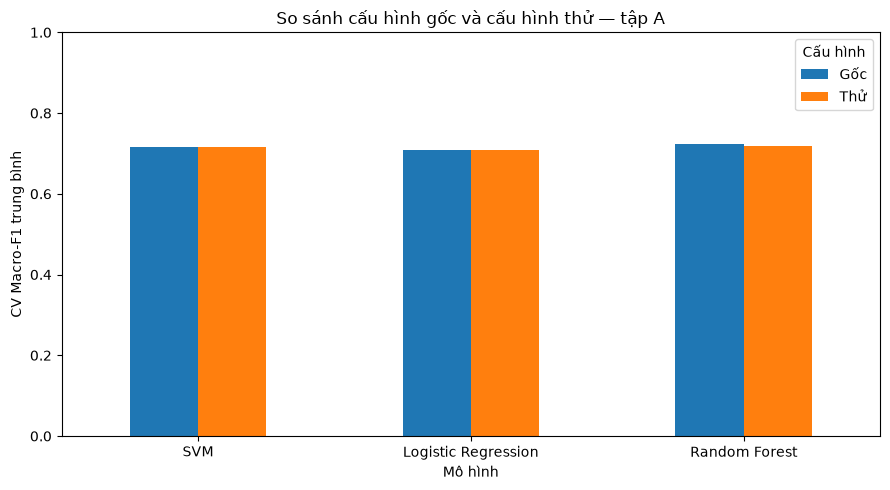


Đã lưu kết quả vào:
C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-16_ThuThamSo_3MoHinh_TapA_Khoi
 - ket_qua.xlsx
 - ket_qua_tong_hop.csv
 - diem_tung_fold.csv
 - so_sanh_goc_va_thu.csv
 - so_sanh_macro_f1.png


In [4]:
output_dir.mkdir(parents=True, exist_ok=True)

excel_path = output_dir / "ket_qua.xlsx"
summary_csv = output_dir / "ket_qua_tong_hop.csv"
fold_csv = output_dir / "diem_tung_fold.csv"
comparison_csv = output_dir / "so_sanh_goc_va_thu.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người thực hiện": "Nguyễn Hoàng Khởi",
    "Ngày thực nghiệm": "16/11/2026",
    "Tập đặc trưng": "A",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_a.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số chính": "CV Macro-F1 trung bình",
    "Thay đổi": (
        "LR: tol 0.0001 -> 0.001; "
        "RF: min_samples_split 2 -> 5; "
        "SVM: shrinking True -> False"
    ),
    "scikit-learn": sklearn.__version__,
}])

results.to_csv(summary_csv, index=False, encoding="utf-8-sig")
fold_results.to_csv(fold_csv, index=False, encoding="utf-8-sig")
comparison.to_csv(comparison_csv, index=False, encoding="utf-8-sig")

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.to_excel(writer, sheet_name="So sanh goc va thu", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin thuc nghiem", index=False)

plot_data = comparison.set_index("model")[["Gốc", "Thử"]]
ax = plot_data.plot(kind="bar", figsize=(9, 5))
ax.set_ylim(0, 1)
ax.set_ylabel("CV Macro-F1 trung bình")
ax.set_xlabel("Mô hình")
ax.set_title("So sánh cấu hình gốc và cấu hình thử — tập A")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Cấu hình")
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(image_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nĐã lưu kết quả vào:")
print(output_dir.resolve())
for path in (excel_path, summary_csv, fold_csv, comparison_csv, image_path):
    print(" -", path.name)


## 5. Nhận xét

Sau khi chạy xong, dựa vào bảng **So sánh cấu hình gốc và cấu hình thử**:

- Chênh lệch dương: cấu hình thử có CV Macro-F1 cao hơn cấu hình gốc.
- Chênh lệch âm: cấu hình gốc có CV Macro-F1 cao hơn cấu hình thử.
- Chênh lệch gần 0: hai cấu hình cho kết quả tương đương trong lần đánh giá này.

Không kết luận trước mô hình nào tốt hơn khi chưa chạy thực nghiệm.